# Preprocesamiento previo a la selección de variables (v2)

**Objetivo.** Dejar las predictoras diarias limpias, completas y auditables antes de crear y seleccionar variables. El modelo pronostica, al cierre del día **D** (23:59), el consumo de frío de **D+1**.

**Punto de partida.** `data/processed/dataset_trabajo.csv`: el dataset horario con las correcciones de fechas del EDA (bloques repetidos, typos de hora, solapamiento entre Excel y días inválidos). Se toma como dado.

**Reglas contra la fuga de información:**

1. La división es cronológica (70 / 15 / 15) y se fija **antes** de cualquier tratamiento.
2. Todo parámetro (umbrales, medianas, métodos elegidos, escalas, LOF) se estima **solo con fechas de Train**.
3. Toda transformación es **causal**: el valor del día *t* depende solo de días ≤ *t*. Por eso se puede transformar la serie completa de una sola vez. En la sección 9 se verifica.
4. El target `y` nunca se modifica.

Toda la lógica vive en `src/preprocesamiento_v2.py`. Esta notebook ajusta cada paso por separado para mostrar sus decisiones y, al final, comprueba que el resultado coincide con el script.

| Sección | Contenido |
|---|---|
| 1 | Datos de partida y división cronológica |
| 2 | Panorama de nulos |
| 3 | Paso 1: columnas no informativas |
| 4 | Paso 2: columnas renombradas entre archivos |
| 5 | Paso 3: columnas duplicadas |
| 6 | Paso 4: clasificación y filtrado por nulos |
| 7 | Paso 5: outliers univariados |
| 8 | Paso 6: imputación con búsqueda del mejor método |
| 9 | Verificación de causalidad e impacto por partición |
| 10 | Análisis multivariado con LOF |
| 11 | Producción del mismo día y consumo de frío |
| 12 | Hipótesis: las metas dependen de la temperatura y de la producción |
| 13 | Exportación y comparación con el script |
| 14 | Conclusiones y decisiones pendientes |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.pipeline import Pipeline

# La notebook puede abrirse desde la raíz o desde la carpeta notebooks.
raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src import preprocesamiento_v2 as pv2
from src.preprocesamiento_v2 import (
    AnalisisLOF, Config, DescartarDuplicadas, DescartarNoInformativas, FiltrarPorNulos,
    ImputarNulos, TratarOutliersUnivariados, UnificarRenombradas,
)

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

# Estilo de gráficos: marcas finas, grilla tenue, paleta categórica en orden fijo.
COLORES = {"train": "#2a78d6", "validation": "#eb6834", "test": "#1baf7a"}
SERIE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({
    "figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.2,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

cfg = Config()
display(pd.Series(vars(cfg), name="valor").to_frame())

,valor
proporciones,"(0.7, 0.15, 0.15)"
patrones_descartar,"(^Id_, ^\.?\d*_, ^Ultimo Dato del Dia_)"
similitud_nombres,0.85
max_solape_renombradas,3
columnas_obligatorias,"(Frio (Kw)_Consolidado EE,)"
hojas_preferidas_duplicados,"(_Totalizadores ,)"
proteger_de_filtro_nulos,"(^Meta ,)"
dias_recientes,60
max_nulos_train,0.3
dias_bloque,7


## 1. Datos de partida y división cronológica

`cargar_datos_diarios` verifica el SHA-256 de `dataset_trabajo.csv` contra `data/checksums.json`, toma el registro de las 23:59 de cada día (los totalizadores se reinician a medianoche, así que el cierre es el total diario) y construye `y` = frío de D+1 buscando la fecha calendario siguiente. La división reutiliza las funciones del pipeline de entrega, así que los cortes son los mismos que en Fase 2.

In [2]:
X, y, cortes, sha = pv2.cargar_datos_diarios(
    pv2.pp.DEFAULT_INPUT_CSV, pv2.pp.DEFAULT_CHECKSUMS_JSON, cfg)
fin_train = cortes["train"][1]
particion = pv2._particion(X.index, y, cortes)

print(f"SHA-256 de entrada verificado: {sha[:16]}...")
print(f"Días: {len(X)} | columnas: {X.shape[1]} | días con y: {y.notna().sum()}")
display(pd.DataFrame({
    "inicio": {p: a.date() for p, (a, b) in cortes.items()},
    "fin": {p: b.date() for p, (a, b) in cortes.items()},
    "días": particion.value_counts(),
}))

SHA-256 de entrada verificado: bd015abb722ba215...
Días: 1172 | columnas: 419 | días con y: 1140


,inicio,fin,días
sin_etiqueta,NaN,NaN,32
test,2023-04-30,2023-10-24,171
train,2020-07-01,2022-10-26,798
validation,2022-10-27,2023-04-29,171


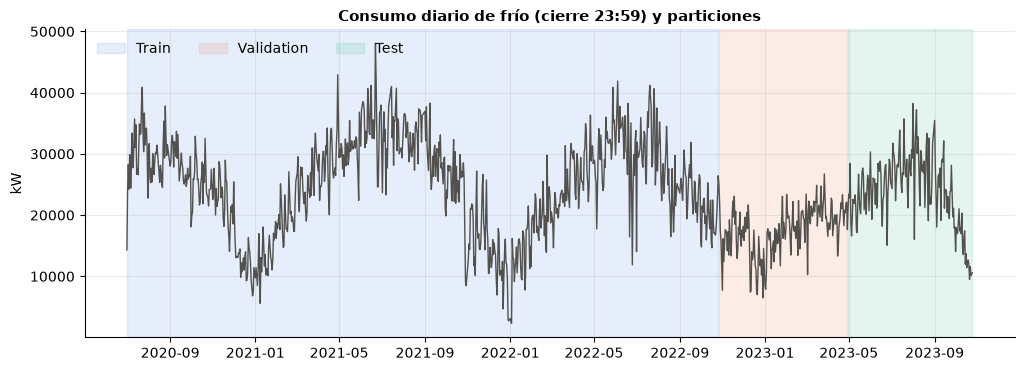

In [3]:
fig, ax = plt.subplots()
ax.plot(X.index, X[pv2.COL_FRIO], color="#52514e", lw=1)
for nombre, (ini, fin) in cortes.items():
    ax.axvspan(ini, fin, color=COLORES[nombre], alpha=0.12, label=nombre.capitalize())
ax.set_title("Consumo diario de frío (cierre 23:59) y particiones")
ax.set_ylabel("kW")
ax.legend(loc="upper left", frameon=False, ncol=3)
plt.show()

Los días sin etiqueta (`sin_etiqueta`) son cierres cuyo día siguiente no existe en el dataset (por un día descartado en la limpieza o porque es el último). No se usan como ejemplos supervisados, pero sí como historia para los métodos que miran días anteriores.

## 2. Panorama de nulos

Antes de tratar nada miramos cuántos nulos hay en Train y cómo se distribuyen en el tiempo. El patrón temporal es lo que permite clasificarlos.

In [4]:
X_train_crudo = X.loc[:fin_train]
nulos_train = X_train_crudo.isna().mean()
rangos = pd.cut(nulos_train, [-0.01, 0, 0.05, 0.20, 0.50, 0.99, 1.0],
                labels=["0 %", "≤5 %", "5–20 %", "20–50 %", "50–99 %", "100 %"])
hoja = pd.Series({c: c.rsplit("_", 1)[-1] for c in X.columns})

display(rangos.value_counts().sort_index().rename_axis("Nulos en Train").to_frame("Columnas"))
display(pd.DataFrame({"columnas": hoja.value_counts(),
                      "% nulos medio en Train": nulos_train.groupby(hoja).mean().mul(100).round(1)})
        .sort_values("% nulos medio en Train", ascending=False))

,Columnas
Nulos en Train,
0 %,235
≤5 %,35
5–20 %,20
20–50 %,78
50–99 %,21
100 %,30


,columnas,% nulos medio en Train
Auxiliar,33,87.5
Seguimiento Dia,1,57.5
Totalizadores Glicol,10,50.4
Consolidado KPI,111,26.2
Totalizadores Aire,10,16.9
Totalizadores Efluentes,7,12.3
Totalizadores CO2,7,12.3
Consolidado GasVapor,19,12.1
Consolidado Agua,22,11.9
Totalizadores Gas y Vapor,23,11.5


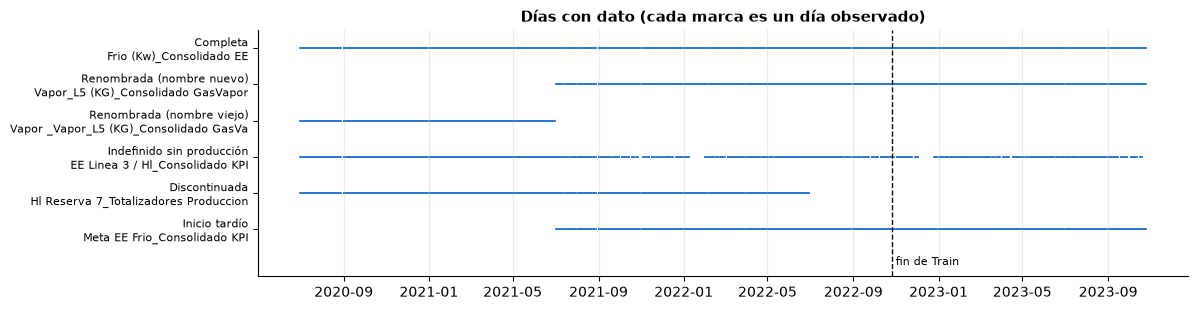

In [5]:
# Presencia en el tiempo de columnas representativas de cada tipo de nulo.
ejemplos = {
    "Meta EE Frio_Consolidado KPI": "Inicio tardío",
    "Hl Reserva 7_Totalizadores Produccion": "Discontinuada",
    "EE Linea 3 / Hl_Consolidado KPI": "Indefinido sin producción",
    "Vapor _Vapor_L5 (KG)_Consolidado GasVapor": "Renombrada (nombre viejo)",
    "Vapor_L5 (KG)_Consolidado GasVapor": "Renombrada (nombre nuevo)",
    "Frio (Kw)_Consolidado EE": "Completa",
}
fig, ax = plt.subplots(figsize=(12, 3.2))
for i, (col, etiqueta) in enumerate(ejemplos.items()):
    presente = X[col].notna()
    ax.scatter(X.index[presente], np.full(presente.sum(), i), s=2, color="#2a78d6", marker="|")
ax.axvline(fin_train, color="#0b0b0b", lw=1, ls="--")
ax.text(fin_train, -0.9, " fin de Train", fontsize=8, va="center")
ax.set_ylim(-1.3, len(ejemplos) - 0.5)
ax.set_yticks(range(len(ejemplos)), [f"{e}\n{c[:38]}" for c, e in ejemplos.items()], fontsize=8)
ax.set_title("Días con dato (cada marca es un día observado)")
ax.grid(axis="y", alpha=0)
plt.show()

Los nulos **no son homogéneos**. Hay columnas que no existían en un Excel (empiezan el 2021-07-02 o el 2022-07-01), columnas que se dejaron de registrar, y KPI por hectolitro que solo faltan los días sin producción. Cada tipo pide un tratamiento distinto, así que imputarlos todos con la mediana sería un error.

## Mecánica de los pasos

Cada paso es una clase con `fit` y `transform`. La función `ajustar` lo ajusta **solo con las fechas de Train** y transforma la serie completa. Es exactamente lo que hace `Pipeline` en el script; acá lo hacemos de a un paso para inspeccionar cada uno.

In [6]:
pasos_ajustados = []

def ajustar(nombre, paso, X_actual):
    # Ajusta con Train, transforma toda la serie y guarda el paso.
    X_fit = X_actual.loc[:fin_train]
    paso.fit(X_fit, y.reindex(X_fit.index))
    pasos_ajustados.append((nombre, paso))
    X_nuevo = paso.transform(X_actual)
    print(f"{nombre}: {X_actual.shape[1]} -> {X_nuevo.shape[1]} columnas")
    return X_nuevo

## 3. Paso 1: columnas no informativas

Se descartan tres tipos de columnas:

* **Metadatos** por patrón de nombre: identificadores `Id_*`, columnas sin encabezado en el Excel (`.3_Auxiliar`) y la hora del último dato.
* **Vacías en Train.**
* **Constantes en Train** (por ejemplo, siempre 0): no aportan variación para aprender.

In [7]:
X1 = ajustar("descartar_no_informativas", DescartarNoInformativas(cfg), X)
rep1 = pasos_ajustados[-1][1].reporte_
motivo_corto = rep1["motivo"].str.replace(r" \(.*\)$", "", regex=True).replace("", "—")
display(pd.crosstab(motivo_corto, rep1["decision"]).rename_axis("Motivo"))
display(rep1[rep1["decision"] == "descartar"].sample(8, random_state=0))

descartar_no_informativas: 419 -> 352 columnas


decision,conservar,descartar
Motivo,,
Constante en Train,0,24
Metadato,0,42
Vacía en Train,0,1
—,352,0


,columna,decision,motivo
356,Id_Totalizadores Aire,descartar,Metadato (patrón ^Id_)
402,.25_Auxiliar,descartar,Metadato (patrón ^\.?\d*_)
380,.3_Auxiliar,descartar,Metadato (patrón ^\.?\d*_)
378,.1_Auxiliar,descartar,Metadato (patrón ^\.?\d*_)
376,Id_Totalizadores Glicol,descartar,Metadato (patrón ^Id_)
394,.17_Auxiliar,descartar,Metadato (patrón ^\.?\d*_)
314,Tot_Vapor_Caldera 3_Totalizadores Gas y Vapor,descartar,Constante en Train (valor 0.0)
388,.11_Auxiliar,descartar,Metadato (patrón ^\.?\d*_)


## 4. Paso 2: columnas renombradas entre archivos

Algunas mediciones cambian de nombre según el Excel. Se detectan como pares con **nombre casi igual** (similitud ≥ 0,85) y **períodos complementarios** (como máximo 3 días con ambas presentes). La serie vieja completa a la nueva y se conserva el nombre más reciente.

Como control se compara el nivel de ambas: la mediana de los primeros 30 días de la nueva contra la de los últimos 30 de la vieja.

In [8]:
X2 = ajustar("unificar_renombradas", UnificarRenombradas(cfg), X1)
display(pasos_ajustados[-1][1].reporte_)

unificar_renombradas: 352 -> 349 columnas


,columna,decision,unida_en,similitud,dias_solapados,fin_vieja,inicio_nueva,ratio_mediana_nueva_vs_vieja
0,Tot L3. L4 y Planta de CO2_Totalizadores Glicol,unificar,"Tot L3, L4 y Planta de CO2_Totalizadores Glicol",1.000,0,2022-06-30,2022-07-01,1.742283
1,Vapor _Vapor_L5 (KG)_Totalizadores Gas y Vapor,unificar,Vapor_L5 (KG)_Totalizadores Gas y Vapor,0.925,0,2021-06-30,2021-07-02,0.810201
2,Vapor _Vapor_L5 (KG)_Consolidado GasVapor,unificar,Vapor_L5 (KG)_Consolidado GasVapor,0.918,0,2021-06-30,2021-07-02,0.810201


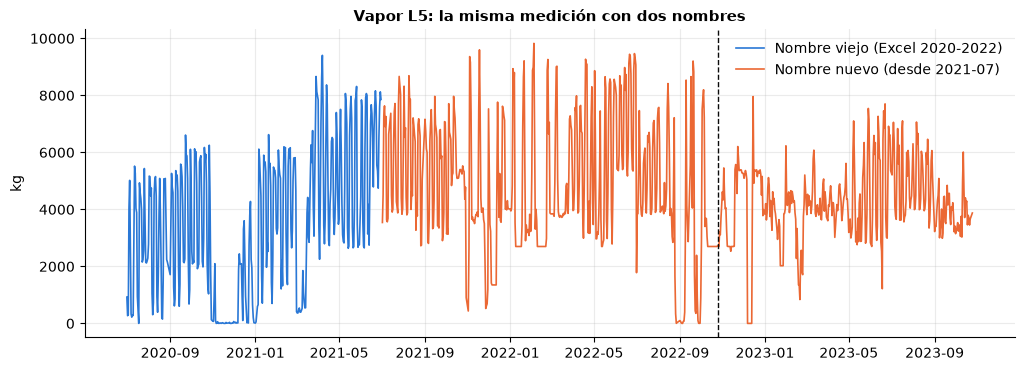

In [9]:
fig, ax = plt.subplots()
vieja, nueva = "Vapor _Vapor_L5 (KG)_Consolidado GasVapor", "Vapor_L5 (KG)_Consolidado GasVapor"
ax.plot(X.index, X[vieja], color=SERIE[0], label="Nombre viejo (Excel 2020-2022)")
ax.plot(X.index, X[nueva], color=SERIE[1], label="Nombre nuevo (desde 2021-07)")
ax.axvline(fin_train, color="#0b0b0b", lw=1, ls="--")
ax.set_title("Vapor L5: la misma medición con dos nombres")
ax.set_ylabel("kg")
ax.legend(frameon=False)
plt.show()

Los dos pares de Vapor L5 muestran continuidad de nivel (cociente 0,81). El par `Tot L3, L4 y Planta de CO2` tiene un cociente de 1,74, así que conviene confirmar con la planta que se trate de la misma medición. Si no lo es, se puede omitir este paso o subir `similitud_nombres`.

## 5. Paso 3: columnas duplicadas

La planilla tiene dos familias de hojas. Las **Totalizadores** son la lectura directa de cada medidor; las **Consolidado** resumen esas lecturas por área y agregan KPI y metas. Muchas mediciones aparecen en las dos con exactamente los mismos valores (por ejemplo, `Hl Cerveza L2` está en *Consolidado Produccion* y en *Totalizadores Produccion*). Una copia no agrega información, así que se conserva una sola.

Una columna se considera copia de otra si en Train tiene los mismos valores (con 6 decimales) y los mismos nulos. Entre copias se conserva, en este orden:

1. Una columna obligatoria: `Frio (Kw)_Consolidado EE`, de la que sale el target.
2. La versión de una hoja **Totalizadores** (`hojas_preferidas_duplicados`).
3. Si no, la primera en el orden original.

Las columnas que existen solo en Consolidado (el frío, las áreas de energía eléctrica, los KPI y las metas) no tienen copia y se conservan. La correlación alta entre columnas *distintas* se deja para la selección de variables.

In [10]:
X3 = ajustar("descartar_duplicadas", DescartarDuplicadas(cfg), X2)
rep3 = pasos_ajustados[-1][1].reporte_
familia = lambda c: c.rsplit("_", 1)[-1].split()[0]
descartadas = rep3[rep3["decision"] == "descartar"]
display(pd.crosstab(descartadas["duplicado_de"].map(familia).rename("Hoja conservada"),
                    descartadas["columna"].map(familia).rename("Hoja descartada")))
display(descartadas.head(12))

descartar_duplicadas: 349 -> 316 columnas

Hoja descartada,Consolidado
Hoja conservada,
Consolidado,7
Totalizadores,26


,columna,decision,duplicado_de
67,Meta Agua Linea 3_Consolidado KPI,descartar,Meta Agua Cocina_Consolidado KPI
79,Meta EE Linea 5_Consolidado KPI,descartar,Meta EE Linea 3_Consolidado KPI
86,Meta EE Eflu_Consolidado KPI,descartar,Meta EE Caldera_Consolidado KPI
87,Meta EE Agua_Consolidado KPI,descartar,Meta EE Caldera_Consolidado KPI
102,Meta Aire Envasado_Consolidado KPI,descartar,Meta Aire Bodega_Consolidado KPI
104,Meta Aire L3_Consolidado KPI,descartar,Meta Aire Bodega_Consolidado KPI
105,Meta Aire L4_Consolidado KPI,descartar,Meta EE Aire_Consolidado KPI
113,Hl Cerveza L2_Consolidado Produccion,descartar,Hl Cerveza L2_Totalizadores Produccion
114,Hl Cerveza L3_Consolidado Produccion,descartar,Hl Cerveza L3_Totalizadores Produccion
115,Hl Cerveza L4_Consolidado Produccion,descartar,Hl Cerveza L4_Totalizadores Produccion


## 6. Paso 4: clasificación y filtrado por nulos

`clasificar_nulos` separa los nulos de cada columna en componentes y asigna el tipo dominante:

| Tipo | Regla | Mecanismo probable |
|---|---|---|
| `vacia` | 100 % nulos | Estructural: no se registra |
| `discontinuada` | sin datos en los últimos 60 días de Train | Estructural: no estará disponible al predecir |
| `inicio_tardio` | la mayoría de los nulos son previos al primer dato | Estructural: la columna no existía en ese Excel |
| `no_aplica_sin_produccion` | KPI "/Hl" cuyos nulos caen (≥ 95 %) en días con producción ≤ 0 | MNAR determinista: el cociente no está definido |
| `bloques` | racha de ≥ 7 días con nulos | Falla prolongada de registro |
| `esporadicos` | rachas cortas | Faltantes aislados |

Además, para cada columna se compara con Mann-Whitney el `y` de los días con nulo y el de los días sin nulo. Un p-valor bajo indica que el faltante no es completamente al azar.

**Decisión:** se descartan las columnas vacías, las discontinuadas y las que superan el 30 % de nulos **efectivos** en Train. Los indefinidos por falta de producción no cuentan como faltantes, porque su valor es conocido.

Las **metas** (`Meta *`) están protegidas del umbral de nulos (`proteger_de_filtro_nulos`). Les falta el primer año completo porque no estaban en el Excel 2020-2022, pero se fijan por adelantado (se conocen al cierre de D) y queremos probar la hipótesis de la sección 12. Igual se descartan si están vacías o discontinuadas.

In [11]:
X4 = ajustar("filtrar_por_nulos", FiltrarPorNulos(cfg), X3)
rep4 = pasos_ajustados[-1][1].reporte_
display(pd.crosstab(rep4["tipo"], rep4["decision"], margins=True, margins_name="Total"))

filtrar_por_nulos: 316 -> 287 columnas


decision,conservar,descartar,Total
tipo,,,
completa,191,0,191
discontinuada,0,3,3
inicio_tardio,44,26,70
no_aplica_sin_produccion,52,0,52
Total,287,29,316


In [12]:
# Verificación de la regla "indefinido sin producción": cada nulo del KPI cae en un día sin producción.
kpi, denominador = "EE Linea 3 / Hl_Consolidado KPI", "Hl Cerveza L3_Consolidado Produccion"
tr = X.loc[:fin_train]
print(pd.crosstab(tr[kpi].isna().map({True: "KPI nulo", False: "KPI con dato"}),
                  (tr[denominador].fillna(0) > 0).map({True: "con producción", False: "sin producción"})))

columnas_ver = ["columna", "tipo", "pct_nulos", "pct_nulos_efectivos", "n_sin_produccion",
                "denominador", "p_valor_y", "decision", "motivo"]
display(rep4.loc[rep4["tipo"] == "no_aplica_sin_produccion", columnas_ver].head(6))

Hl Cerveza L3_Consolidado Produccion  con producción  sin producción
EE Linea 3 / Hl_Consolidado KPI                                     
KPI con dato                                     641              73
KPI nulo                                           0             105


,columna,tipo,pct_nulos,pct_nulos_efectivos,n_sin_produccion,denominador,p_valor_y,decision,motivo
0,EE Planta / Hl_Consolidado KPI,no_aplica_sin_produccion,0.010989,0.0,9,Hl de Mosto_Consolidado Produccion,NaN,conservar,
1,EE Elaboracion / Hl_Consolidado KPI,no_aplica_sin_produccion,0.010989,0.0,9,Hl de Mosto_Consolidado Produccion,NaN,conservar,
2,EE Bodega / Hl_Consolidado KPI,no_aplica_sin_produccion,0.010989,0.0,9,Hl de Mosto_Consolidado Produccion,NaN,conservar,
3,EE Cocina / Hl_Consolidado KPI,no_aplica_sin_produccion,0.056166,0.0,46,Hl de Mosto_Consolidado Produccion,NaN,conservar,
4,EE Envasado / Hl_Consolidado KPI,no_aplica_sin_produccion,0.010989,0.0,9,Hl de Mosto_Consolidado Produccion,NaN,conservar,
5,EE Linea 2 / Hl_Consolidado KPI,no_aplica_sin_produccion,0.092796,0.0,76,HL Mosto Amstel_Totalizadores Produccion,NaN,conservar,


In [13]:
print("Columnas descartadas por motivo:")
motivo4 = rep4.loc[rep4["decision"] == "descartar", "motivo"].str.replace(
    r"^\d+\.\d+% de nulos efectivos.*", "Más de 30 % de nulos efectivos en Train", regex=True)
display(motivo4.value_counts().to_frame("columnas"))
display(rep4.loc[rep4["decision"] == "descartar", columnas_ver].sort_values("pct_nulos_efectivos").head(10))

Columnas descartadas por motivo:


,columnas
motivo,
Más de 30 % de nulos efectivos en Train,26
Estructural: dejó de registrarse antes del fin de Train,3


,columna,tipo,pct_nulos,pct_nulos_efectivos,n_sin_produccion,denominador,p_valor_y,decision,motivo
129,Cocimientos Diarios_Totalizadores Produccion,inicio_tardio,0.305250,0.305250,0,NaN,1.614089e-07,descartar,30.5% de nulos efectivos en Train (> 30%)
130,Nivel Silo Bagazo Norte (1)_Totalizadores Produccion,inicio_tardio,0.366300,0.366300,0,NaN,8.211606e-04,descartar,36.6% de nulos efectivos en Train (> 30%)
131,Nivel Silo Bagazo Sur (2)_Totalizadores Produccion,inicio_tardio,0.366300,0.366300,0,NaN,8.211606e-04,descartar,36.6% de nulos efectivos en Train (> 30%)
294,Tot Aire Expulsion_Totalizadores Aire,inicio_tardio,0.415140,0.415140,0,NaN,7.068731e-01,descartar,41.5% de nulos efectivos en Train (> 30%)
295,Tot Aire Servicio Logistica_Totalizadores Aire,inicio_tardio,0.415140,0.415140,0,NaN,7.068731e-01,descartar,41.5% de nulos efectivos en Train (> 30%)
56,Agua Lavadora L3 / Hl_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,descartar,43.5% de nulos efectivos en Train (> 30%)
57,Agua Paste L3 / Hl_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,descartar,43.5% de nulos efectivos en Train (> 30%)
50,Aire Expulsion / Hl_Consolidado KPI,inicio_tardio,0.490842,0.434676,46,Hl de Mosto_Consolidado Produccion,9.160174e-01,descartar,43.5% de nulos efectivos en Train (> 30%)
209,Agua Paste L3_Consolidado Agua,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,descartar,43.5% de nulos efectivos en Train (> 30%)
210,Agua Lavadora L3_Consolidado Agua,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,descartar,43.5% de nulos efectivos en Train (> 30%)


In [14]:
display(rep4.loc[rep4["protegida"], columnas_ver].head(5))
print(f"Metas protegidas y conservadas: {int((rep4['protegida'] & (rep4['decision'] == 'conservar')).sum())}")

,columna,tipo,pct_nulos,pct_nulos_efectivos,n_sin_produccion,denominador,p_valor_y,decision,motivo
58,Meta EE Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,0.347747,conservar,Protegida del umbral de nulos
59,Meta Agua Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,0.347747,conservar,Protegida del umbral de nulos
60,Meta ET Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,0.347747,conservar,Protegida del umbral de nulos
61,Meta Aire Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,0.347747,conservar,Protegida del umbral de nulos
62,Meta Agua Elab_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,0.347747,conservar,Protegida del umbral de nulos


Metas protegidas y conservadas: 43


In [15]:
# Asociación de los nulos con y (solo columnas conservadas con nulos efectivos).
con_test = rep4[(rep4["decision"] == "conservar") & rep4["p_valor_y"].notna()]
print(f"Columnas conservadas con test de asociación: {len(con_test)}")
display(con_test[columnas_ver].sort_values("p_valor_y").head(8))

Columnas conservadas con test de asociación: 47


,columna,tipo,pct_nulos,pct_nulos_efectivos,n_sin_produccion,denominador,p_valor_y,decision,motivo
310,Tot Trasiego_Totalizadores Glicol,inicio_tardio,0.084249,0.084249,0,NaN,5.977197e-10,conservar,
26,Agua Linea 5/Hl_Consolidado KPI,no_aplica_sin_produccion,0.340659,0.024420,259,HL Mosto Amstel_Totalizadores Produccion,2.651167e-05,conservar,
48,Aire L5 / Hl_Consolidado KPI,no_aplica_sin_produccion,0.340659,0.024420,259,HL Mosto Amstel_Totalizadores Produccion,2.651167e-05,conservar,
38,ET Linea 5/Hl_Consolidado KPI,no_aplica_sin_produccion,0.340659,0.024420,259,HL Mosto Amstel_Totalizadores Produccion,2.651167e-05,conservar,
59,Meta Agua Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,conservar,Protegida del umbral de nulos
60,Meta ET Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,conservar,Protegida del umbral de nulos
61,Meta Aire Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,conservar,Protegida del umbral de nulos
58,Meta EE Planta_Consolidado KPI,inicio_tardio,0.434676,0.434676,0,NaN,3.477474e-01,conservar,Protegida del umbral de nulos


Las metas empiezan en julio de 2021, así que en Train tienen alrededor de 43 % de nulos: sin la protección, el umbral de 30 % las descartaría. Su primer año se imputa en el paso 6 y queda marcado con un indicador.

## 7. Paso 5: outliers univariados

Se tratan dos niveles distintos, ambos con parámetros de Train:

1. **Error grueso** (físicamente imposible): un valor negativo en una variable que en Train es ≥ 0, o un valor mayor a 5 × P99. Son errores del medidor, del orden de millones. Pasan a NaN y los completa el paso 6.
2. **Extremo** (posible pero atípico): fuera de los límites del detector elegido. Se **winsoriza** solo por arriba: un total diario bajo es físicamente posible porque el equipo pudo trabajar menos.

Cuando más del 5 % de Train son ceros (días sin producción), los ceros no entran al cálculo de límites y no se recortan. Se calculan los tres detectores para compararlos y se aplica el elegido en `Config` (IQR con k = 3).

In [16]:
X5 = ajustar("outliers_univariados", TratarOutliersUnivariados(cfg), X4)
paso5 = pasos_ajustados[-1][1]
display(paso5.tablas_["comparacion_detectores"])
rep5 = paso5.reporte_
print(f"Errores gruesos en Train: {rep5['n_errores_train'].sum()} valores en "
      f"{(rep5['n_errores_train'] > 0).sum()} columnas")
display(rep5.sort_values("n_errores_train", ascending=False)
        [["columna", "no_negativa", "ceros_frecuentes", "tope_error_grueso",
          "n_errores_train", "iqr_sup", "iqr_n_extremos_train"]].head(8))

outliers_univariados: 287 -> 287 columnas


,detector,valores_extremos_train,pct_valores_train,columnas_afectadas,elegido
0,iqr,2132,0.009816,103,True
1,mad,3745,0.017242,130,False
2,percentil,1020,0.004696,240,False


Errores gruesos en Train: 281 valores en 91 columnas


,columna,no_negativa,ceros_frecuentes,tope_error_grueso,n_errores_train,iqr_sup,iqr_n_extremos_train
15,EE Agua / Hl_Consolidado KPI,True,False,1.810037,9,0.224208,13
139,Prod Agua (Kw)_Consolidado EE,True,False,6998.500000,7,2417.750000,0
285,Totalizador Bba P51_Totalizadores Efluentes,True,True,80121.132000,7,1893.922500,112
110,HL Mosto Roja_Totalizadores Produccion,True,True,2099.200000,7,2201.750000,0
281,Totalizador Bba P1_Totalizadores Efluentes,True,False,26126.449000,7,2446.252500,3
267,Tot Aire Expulsion_Consolidado Aire,True,True,57933.467000,7,18770.770000,0
2,EE Bodega / Hl_Consolidado KPI,True,False,15.390878,6,1.536233,31
27,Agua Servicios/Hl_Consolidado KPI,True,False,20.144207,6,2.845383,19


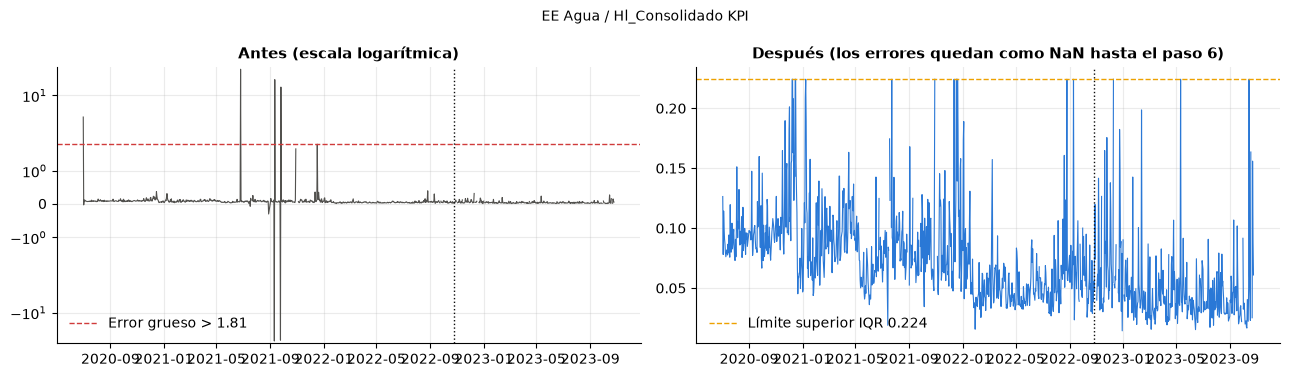

In [17]:
# Ejemplo: la columna con más errores gruesos, antes y después del tratamiento.
col = rep5.sort_values("n_errores_train", ascending=False)["columna"].iloc[0]
lim = paso5.limites_[col]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(X4.index, X4[col], color="#52514e", lw=0.8)
axes[0].axhline(lim["tope"], color="#d03b3b", ls="--", lw=1, label=f"Error grueso > {lim['tope']:,.3g}")
axes[0].set_yscale("symlog")
axes[0].set_title("Antes (escala logarítmica)")
axes[0].legend(frameon=False)
axes[1].plot(X5.index, X5[col], color=SERIE[0], lw=0.8)
axes[1].axhline(lim["sup"], color="#eda100", ls="--", lw=1, label=f"Límite superior IQR {lim['sup']:,.3g}")
axes[1].set_title("Después (los errores quedan como NaN hasta el paso 6)")
axes[1].legend(frameon=False)
for ax in axes:
    ax.axvline(fin_train, color="#0b0b0b", lw=1, ls=":")
fig.suptitle(col, fontsize=10)
plt.tight_layout()
plt.show()

## 8. Paso 6: imputación con búsqueda del mejor método

Para cada columna se elige el método con **menor error simulado en Train**:

1. Se ocultan valores observados de Train imitando los nulos reales de esa columna: rachas del mismo largo (10 %, mínimo 30 valores) y, si la columna empieza tarde, un bloque al comienzo de la serie. En ese bloque los métodos que miran días previos no tienen historia, igual que en el primer año real de las metas.
2. Se completan con cada método candidato y se mide **MAE / IQR**, que es comparable entre columnas de distinta escala.
3. Gana el menor error. Ante un empate, gana el método más simple.

Todos los candidatos son causales (usan solo días anteriores o estadísticos de Train): `mediana_train`, `ffill_3` (arrastre de hasta 3 días calendario), `mediana_dia_semana`, `mediana_mes` (mediana del mismo mes calendario en Train, pensada para las metas mensuales), `media_movil_7` (media de los 7 días previos) y `lag_7` (mismo día de la semana anterior). La interpolación lineal o el relleno hacia atrás usarían el futuro y quedan excluidos.

Los KPI indefinidos por falta de producción se completan con **0**: la columna de producción ya indica que ese día no se produjo. Las columnas con más de 5 % de nulos efectivos reciben un indicador `<col>__imputado`. Las que faltan exactamente los mismos días (por ejemplo, todas las metas) comparten **un único** indicador.

In [18]:
X6 = ajustar("imputar_nulos", ImputarNulos(cfg), X5)
paso6 = pasos_ajustados[-1][1]
rep6, busqueda = paso6.reporte_, paso6.tablas_["busqueda_imputacion"]

resumen_metodos = (busqueda.groupby("metodo")["mae_relativo"].median().rename("MAE/IQR mediano")
                   .to_frame().join(rep6["metodo_elegido"].value_counts().rename("veces elegido"))
                   .fillna(0).sort_values("MAE/IQR mediano"))
display(resumen_metodos)

ganancia = (1 - rep6["mae_relativo_elegido"] / rep6["mae_relativo_mediana"]).dropna()
print(f"Reducción mediana del error frente a imputar siempre con la mediana: {ganancia.median():.0%}")
print(f"Nulos que quedan: {int(X6.isna().sum().sum())} | indicadores agregados: {paso6.con_indicador_}")

imputar_nulos: 287 -> 289 columnas


,MAE/IQR mediano,veces elegido
metodo,,
media_movil_7,0.476507,49
ffill_3,0.481521,82
lag_7,0.531868,27
mediana_mes,0.545711,44
mediana_dia_semana,0.590256,22
mediana_train,0.593018,63


Reducción mediana del error frente a imputar siempre con la mediana: 23%
Nulos que quedan: 0 | indicadores agregados: ['Meta EE Planta_Consolidado KPI', 'Tot  Trasiego_Totalizadores Glicol']


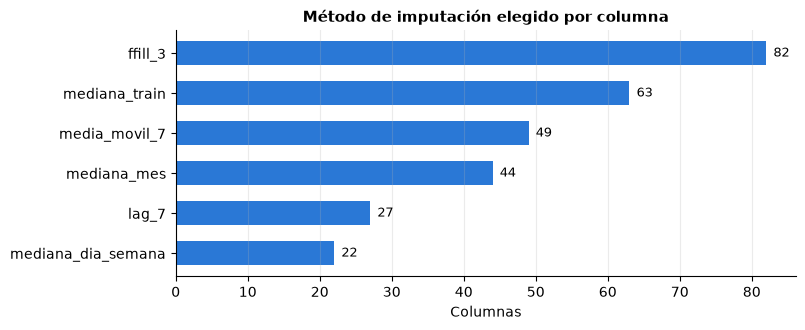

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.2))
orden = resumen_metodos.sort_values("veces elegido")
ax.barh(orden.index, orden["veces elegido"], color=SERIE[0], height=0.6)
for i, v in enumerate(orden["veces elegido"]):
    ax.text(v + 1, i, f"{int(v)}", va="center", fontsize=9)
ax.set_title("Método de imputación elegido por columna")
ax.set_xlabel("Columnas")
ax.grid(axis="y", alpha=0)
plt.show()

In [20]:
# Detalle de las columnas con más nulos efectivos.
display(rep6.sort_values("pct_nulos_efectivos", ascending=False)
        [["columna", "pct_nulos_efectivos", "completados_con_cero_sin_produccion",
          "metodo_elegido", "mae_relativo_elegido", "mae_relativo_mediana", "agrega_indicador"]].head(10))

,columna,pct_nulos_efectivos,completados_con_cero_sin_produccion,metodo_elegido,mae_relativo_elegido,mae_relativo_mediana,agrega_indicador
69,Meta EE Cocina_Consolidado KPI,0.434676,0,mediana_train,0.593692,0.593692,True
65,Meta Agua Servicios_Consolidado KPI,0.434676,0,mediana_train,0.223701,0.223701,True
64,Meta Agua Linea 5_Consolidado KPI,0.434676,0,mediana_train,0.223701,0.223701,True
63,Meta Agua Linea 4_Consolidado KPI,0.434676,0,mediana_train,0.223701,0.223701,True
62,Meta Agua Linea 2_Consolidado KPI,0.434676,0,mediana_train,0.223701,0.223701,True
57,Meta Aire Planta_Consolidado KPI,0.434676,0,mediana_train,0.593692,0.593692,True
56,Meta ET Planta_Consolidado KPI,0.434676,0,mediana_mes,0.335622,0.601670,True
55,Meta Agua Planta_Consolidado KPI,0.434676,0,mediana_train,0.223701,0.223701,True
54,Meta EE Planta_Consolidado KPI,0.434676,0,mediana_train,0.593692,0.593692,True
70,Meta EE Envasado_Consolidado KPI,0.434676,0,mediana_train,0.593692,0.593692,True


In [21]:
metas6 = rep6[rep6["columna"].str.startswith("Meta ")]
resumen_metas = metas6.groupby("metodo_elegido")["columna"].agg(
    metas="count", ejemplos=lambda s: ", ".join(s.str.split("_").str[0].head(4)))
display(resumen_metas)

,metas,ejemplos
metodo_elegido,,
mediana_mes,10,"Meta ET Planta, Meta ET Elab, Meta ET Bodega, Meta ET Cocina"
mediana_train,33,"Meta EE Planta, Meta Agua Planta, Meta Aire Planta, Meta Agua Elab"


Que los métodos temporales (`ffill_3`, `media_movil_7`) ganen en la mayoría de las columnas confirma lo esperable en una serie diaria: el valor de ayer predice mejor que la mediana de todo Train.

En las metas, la mediana del mismo mes solo mejora a la mediana global en las de **energía térmica** (`Meta ET`), que tienen estacionalidad. Las metas de energía eléctrica cambian sobre todo con la revisión anual de julio, no con la estación, así que el mes no ayuda a reconstruir el primer año.

## 9. Verificación de causalidad e impacto por partición

**Causalidad.** Si transformar la historia hasta una fecha da exactamente lo mismo que transformar toda la serie y recortar en esa fecha, ningún paso usa información futura. Se prueba en el fin de Train, en el fin de Validation y dentro de Test.

**Impacto.** Cuántos valores modificó cada paso en cada partición. Si un tratamiento modifica mucho más Validation o Test que Train, los límites de Train no representan bien el período nuevo.

In [22]:
pipeline = Pipeline(pasos_ajustados)
causalidad = pv2.verificar_causalidad(
    pipeline, X, [fin_train, cortes["validation"][1], cortes["test"][0] + pd.Timedelta(days=30)])
display(causalidad)
assert causalidad["causal"].all(), "Algún paso usa información futura"

X_proc = X6
impacto = pv2.impacto_por_paso(pipeline, X, particion)
tabla_impacto = impacto.pivot(index="paso", columns="particion", values="pct_valores").mul(100).round(2)
display(tabla_impacto.loc[[n for n, _ in pasos_ajustados], ["train", "validation", "test", "sin_etiqueta"]]
        .rename(columns=lambda c: f"% {c}"))

,corte,filas,max_diferencia,causal
0,2022-10-26,819,0.0,True
1,2023-04-29,997,0.0,True
2,2023-05-30,1028,0.0,True


particion,% train,% validation,% test,% sin_etiqueta
paso,,,,
descartar_no_informativas,0.00,0.00,0.00,0.00
unificar_renombradas,0.37,0.00,0.00,0.25
descartar_duplicadas,0.00,0.00,0.00,0.00
filtrar_por_nulos,0.00,0.00,0.00,0.00
outliers_univariados,1.02,1.58,1.34,1.32
imputar_nulos,7.70,3.11,2.22,6.13


In [23]:
display(impacto[impacto["paso"] == "outliers_univariados"][["particion", "valores_modificados", "top_columnas"]])

,particion,valores_modificados,top_columnas
16,sin_etiqueta,121,Totalizador Bba P51_Totalizadores Efluentes (8); CO 2 Linea 4 / Hl_Consolidado KPI (7)...
17,test,657,CO 2 Linea 4 / Hl_Consolidado KPI (110); Totalizador_L2_Barriles_Totalizadores CO2 (44...
18,train,2341,TOT AGUA DESAIREADA_Totalizadores Gas y Vapor (154); Agua Enjuagadora L2_Totalizadores...
19,validation,775,Totalizador Bba P51_Totalizadores Efluentes (86); CO 2 Linea 4 / Hl_Consolidado KPI (7...


## 10. Análisis multivariado con LOF

Local Outlier Factor detecta días que son raros por la **combinación** de valores, aunque cada variable por separado esté en rango. Este paso no modifica los datos: marca días.

* Estandarización y PCA (90 % de varianza) ajustados en Train. Se usa `StandardScaler` y no `RobustScaler` porque las columnas con casi todos ceros tienen IQR ≈ 0, y el escalado robusto las amplifica a valores z de miles, lo que degenera el LOF. Los extremos ya fueron winsorizados.
* **Búsqueda de `n_neighbors`:** se prueba una grilla y se elige el valor cuyo conjunto de días anómalos es más estable (mayor Jaccard medio con el resto).
* Train se puntúa con el ajuste. Validation y Test se puntúan con `novelty=True`, es decir, comparados contra Train sin reajustar.
* Un día se marca como anómalo si su LOF es mayor a 1,5.

In [24]:
lof = AnalisisLOF(cfg).fit(X_proc.loc[:fin_train])
anomalias = lof.puntuar(X_proc).assign(particion=particion)
display(lof.sensibilidad_)
print(f"n_neighbors elegido: {lof.k_} | componentes PCA: {lof.pca_.n_components_}")
display(anomalias.groupby("particion")["anomalo_lof"].agg(["sum", "count", "mean"])
        .rename(columns={"sum": "anómalos", "count": "días", "mean": "proporción"}))

,n_neighbors,dias_anomalos_train,jaccard_medio
0,10,16,0.531373
1,20,13,0.591036
2,35,11,0.600840
3,50,10,0.384314


n_neighbors elegido: 35 | componentes PCA: 59


,anómalos,días,proporción
particion,,,
sin_etiqueta,8,32,0.250000
test,114,171,0.666667
train,10,798,0.012531
validation,74,171,0.432749


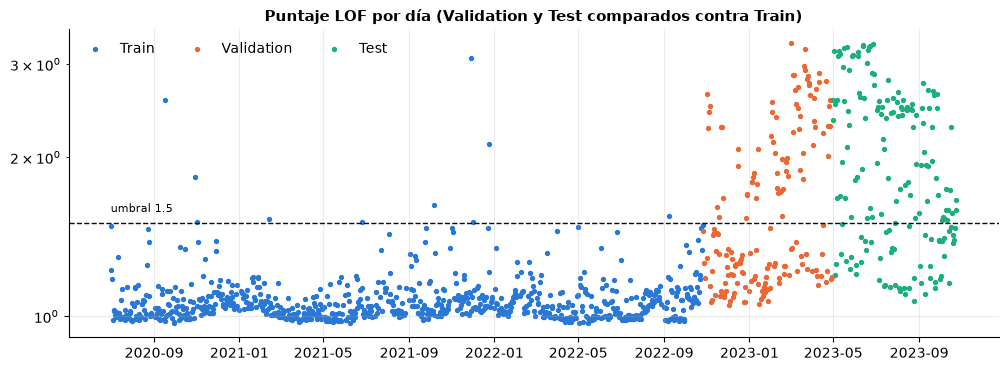

In [25]:
fig, ax = plt.subplots()
for nombre in ("train", "validation", "test"):
    parte = anomalias[anomalias["particion"] == nombre]
    ax.scatter(parte.index, parte["lof_score"], s=8, color=COLORES[nombre], label=nombre.capitalize())
ax.axhline(cfg.lof_umbral, color="#0b0b0b", ls="--", lw=1)
ax.text(X.index.min(), cfg.lof_umbral * 1.05, f"umbral {cfg.lof_umbral}", fontsize=8)
ax.set_yscale("log")
ax.set_title("Puntaje LOF por día (Validation y Test comparados contra Train)")
ax.legend(frameon=False, ncol=3)
plt.show()

In [26]:
# ¿Qué variables explican los días anómalos de cada partición?
for nombre in ("train", "validation", "test"):
    marcados = anomalias[(anomalias["particion"] == nombre) & anomalias["anomalo_lof"]]
    top = marcados["variables_mas_atipicas"].str.split(", ").explode().value_counts().head(5)
    print(f"\n{nombre.upper()} ({len(marcados)} días anómalos):")
    print(top.to_string())


TRAIN (10 días anómalos):
variables_mas_atipicas
Totalizador Bba Envasado_Totalizadores Efluentes    2
KW Enfluentes Hidr_Totalizadores Energia            2
Agua Helada Cocina_Totalizadores Agua               2
HL Mosto Amstel_Totalizadores Produccion            2
Agua Linea 4/Hl_Consolidado KPI                     2

VALIDATION (74 días anómalos):
variables_mas_atipicas
Totalizador_L2_Barriles_Totalizadores CO2               74
KW Mycom 2_Totalizadores Energia                        52
KW Mycom 1_Totalizadores Energia                        48
CAUDAL DE GAS CALDERA 1 M3_Totalizadores Gas y Vapor    28
KW Trafo 12_Totalizadores Energia                       26

TEST (114 días anómalos):
variables_mas_atipicas
Totalizador_L2_Barriles_Totalizadores CO2    113
KW Secador Kaeser_Totalizadores Energia       91
KW Mycom 1_Totalizadores Energia              72
KW Mycom 2_Totalizadores Energia              39
Red  Bodega Interno_Totalizadores Agua        30


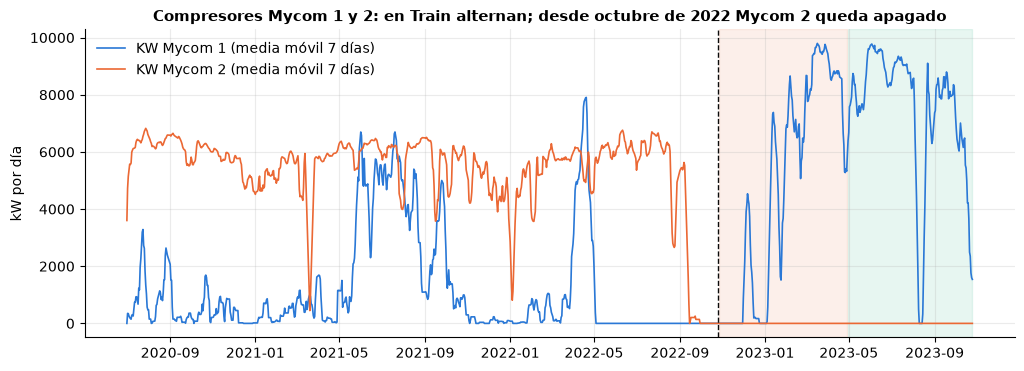

In [27]:
# Cambio de régimen: en Train los compresores alternan; desde fines de 2022 solo opera Mycom 1.
fig, ax = plt.subplots()
for i, col in enumerate(["KW Mycom 1_Totalizadores Energia", "KW Mycom 2_Totalizadores Energia"]):
    ax.plot(X_proc.index, X_proc[col].rolling(7, min_periods=1).mean(), color=SERIE[i],
            label=col.split("_")[0] + " (media móvil 7 días)")
for nombre, (ini, fin) in cortes.items():
    if nombre != "train":
        ax.axvspan(ini, fin, color=COLORES[nombre], alpha=0.10)
ax.axvline(fin_train, color="#0b0b0b", lw=1, ls="--")
ax.set_title("Compresores Mycom 1 y 2: en Train alternan; desde octubre de 2022 Mycom 2 queda apagado")
ax.set_ylabel("kW por día")
ax.legend(frameon=False)
plt.show()

**Lectura.** En Train el LOF marca pocos días (alrededor del 2 %). En Validation y Test marca casi la mitad, y las variables responsables son siempre las mismas: los compresores Mycom 1 y 2 y la línea de barriles L2. No son errores de medición sino un **cambio de régimen operativo** posterior a Train: durante Train los dos compresores se alternaban (Mycom 1 cubría sobre todo los picos de verano), y desde octubre de 2022 Mycom 2 queda apagado y Mycom 1 cubre toda la carga. Además, la línea de barriles L2, casi inactiva en Train, entra en operación. Por eso la decisión por defecto es `tratamiento_lof="reportar"`: eliminar días de Validation o Test nunca es válido, y en Train hay pocos marcados. La alternativa `"excluir_train"` está disponible para compararla en el modelado.

## 11. Producción del mismo día y consumo de frío

La consigna sugiere que el frío depende del volumen de producción y de la etapa de fermentación. Medimos esa relación **solo en Train** y con tres preguntas:

1. **Directa:** Spearman de cada volumen de producción del día D con el frío de D y con `y` (frío de D+1).
2. **Sin la estación:** en verano se produce más cerveza y también hace más calor, así que parte de la correlación puede venir de la estación. Repetimos la medición sobre los residuos (en rangos) de regresar cada variable contra la temperatura media de 7 días de Open-Meteo.
3. **Además de la persistencia:** el frío de hoy y su media de 7 días ya predicen bien a `y`. Medimos la correlación de la producción con lo que esas dos **no** explican. Esta es la pregunta que importa para el modelo.

In [28]:
clima = pd.read_csv(raiz / "data" / "reference" / "clima_tecate_openmeteo.csv",
                    parse_dates=["DIA"]).set_index("DIA")
tr = X.loc[:fin_train]
y_tr = y.reindex(tr.index)
frio_tr = tr[pv2.COL_FRIO]
temp7 = clima["temp_media_c"].rolling(7, min_periods=1).mean().reindex(tr.index)

def residuo(serie, controles):
    # Residuo de una regresión lineal (ajustada en Train) de `serie` sobre `controles`.
    ok = serie.notna() & controles.notna().all(axis=1)
    A = np.c_[np.ones(ok.sum()), controles[ok].to_numpy()]
    coef = np.linalg.lstsq(A, serie[ok].to_numpy(), rcond=None)[0]
    res = pd.Series(np.nan, index=serie.index)
    res[ok] = serie[ok] - A @ coef
    return res

control_temp = temp7.to_frame("temp7")
y_sin_temp = residuo(y_tr.rank(), control_temp)
frio_sin_temp = residuo(frio_tr.rank(), control_temp)
persistencia = pd.DataFrame({"frio_D": frio_tr,
                             "frio_media7": frio_tr.asfreq("D").rolling(7, min_periods=4).mean().reindex(tr.index)})
y_no_explicado = residuo(y_tr, persistencia)

produccion = ["Hl de Mosto", "Hl Cerveza Cocina", "Hl Producido Bodega", "Hl Cerveza Filtrada",
              "Hl Cerveza Envasada", "Hl Cerveza L2", "Hl Cerveza L3", "Hl Cerveza L4",
              "Hl Cerveza L5", "Cocimientos Diarios"]
filas = []
for nombre in produccion:
    s = tr[f"{nombre}_Consolidado Produccion"]
    s_sin_temp = residuo(s.rank(), control_temp)
    filas.append({
        "variable": nombre,
        "frío D": s.corr(frio_tr, method="spearman"),
        "y (D+1)": s.corr(y_tr, method="spearman"),
        "frío D sin temperatura": s_sin_temp.corr(frio_sin_temp),
        "y sin temperatura": s_sin_temp.corr(y_sin_temp),
        "y no explicado por persistencia": s.corr(y_no_explicado, method="spearman"),
        "% días en 0": (s == 0).mean() * 100,
    })
tabla_prod = pd.DataFrame(filas).set_index("variable")
print(f"Temperatura (media 7 días) vs frío D: {temp7.corr(frio_tr, method='spearman'):.2f} | "
      f"vs y: {temp7.corr(y_tr, method='spearman'):.2f}")
display(tabla_prod.round(2))

Temperatura (media 7 días) vs frío D: 0.54 | vs y: 0.53

,frío D,y (D+1),frío D sin temperatura,y sin temperatura,y no explicado por persistencia,% días en 0
variable,,,,,,
Hl de Mosto,0.40,0.33,0.45,0.38,0.03,8.18
Hl Cerveza Cocina,0.39,0.34,0.43,0.38,0.05,8.18
Hl Producido Bodega,0.58,0.52,0.62,0.54,0.11,1.10
Hl Cerveza Filtrada,0.54,0.42,0.54,0.40,-0.05,2.69
Hl Cerveza Envasada,0.50,0.47,0.50,0.45,0.13,3.05
Hl Cerveza L2,0.30,0.25,0.31,0.25,0.06,15.87
Hl Cerveza L3,0.30,0.29,0.31,0.30,0.14,21.73
Hl Cerveza L4,0.29,0.25,0.31,0.27,0.01,10.74
Hl Cerveza L5,0.32,0.27,0.30,0.24,0.06,58.00


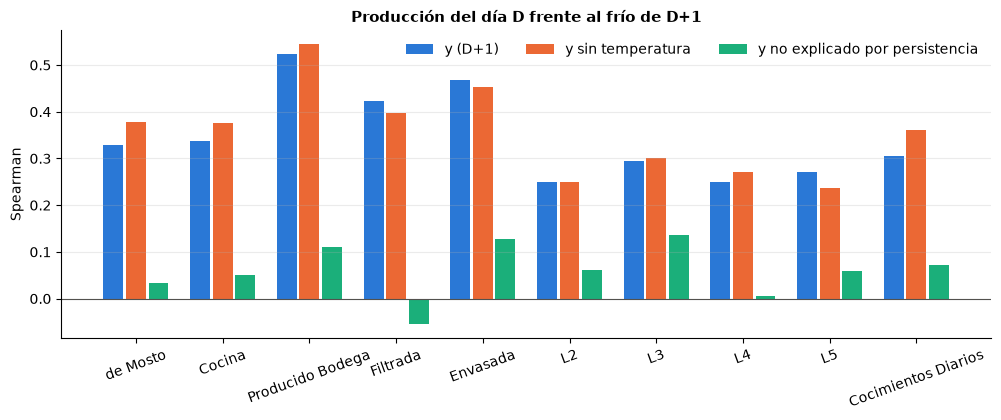

In [29]:
fig, ax = plt.subplots(figsize=(12, 4))
cols = ["y (D+1)", "y sin temperatura", "y no explicado por persistencia"]
ancho = 0.26
pos = np.arange(len(tabla_prod))
for i, col in enumerate(cols):
    ax.bar(pos + (i - 1) * ancho, tabla_prod[col], width=ancho - 0.03, color=SERIE[i], label=col)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(pos, [v.replace("Hl ", "").replace("Cerveza ", "") for v in tabla_prod.index], rotation=20)
ax.set_ylabel("Spearman")
ax.set_title("Producción del día D frente al frío de D+1")
ax.legend(frameon=False, ncol=3, loc="upper right")
ax.grid(axis="x", alpha=0)
plt.show()

**Rezagos y acumulados.** La cerveza que entra a fermentar hoy necesita frío durante varios días. Si eso se refleja en el consumo, el volumen producido días atrás, o acumulado en una ventana, debería relacionarse con `y` incluso más que el del mismo día. Todas las ventanas usan solo días ≤ D.

In [30]:
rezagos = [0, 1, 2, 3, 5, 7, 10, 14]
filas = {}
for nombre in ["Hl de Mosto", "Hl Producido Bodega", "Hl Cerveza Filtrada", "Hl Cerveza Envasada"]:
    s = tr[f"{nombre}_Consolidado Produccion"].asfreq("D")
    fila = {f"D-{k}": residuo(s.shift(k).reindex(tr.index).rank(), control_temp).corr(y_sin_temp)
            for k in rezagos}
    for v in (7, 14):
        acumulado = s.rolling(v, min_periods=v // 2).sum().reindex(tr.index)
        fila[f"suma {v} días"] = residuo(acumulado.rank(), control_temp).corr(y_sin_temp)
        fila[f"suma {v} días, además de persistencia"] = acumulado.corr(y_no_explicado, method="spearman")
    filas[nombre] = fila
print("Spearman con y, sin el efecto de la temperatura (Train):")
display(pd.DataFrame(filas).T.round(2))

Spearman con y, sin el efecto de la temperatura (Train):


,D-0,D-1,D-2,D-3,D-5,D-7,D-10,D-14,suma 7 días,"suma 7 días, además de persistencia",suma 14 días,"suma 14 días, además de persistencia"
Hl de Mosto,0.38,0.32,0.30,0.29,0.28,0.34,0.34,0.25,0.51,-0.00,0.60,0.05
Hl Producido Bodega,0.54,0.42,0.37,0.37,0.43,0.48,0.45,0.42,0.55,0.02,0.61,0.06
Hl Cerveza Filtrada,0.40,0.33,0.35,0.36,0.42,0.36,0.37,0.36,0.57,0.04,0.61,0.07
Hl Cerveza Envasada,0.45,0.32,0.28,0.27,0.38,0.38,0.33,0.36,0.54,0.05,0.58,0.07


In [31]:
perfil = pd.DataFrame({
    "Frío": tr[pv2.COL_FRIO],
    "Hl Bodega": tr["Hl Producido Bodega_Consolidado Produccion"],
    "Hl Envasada": tr["Hl Cerveza Envasada_Consolidado Produccion"],
    "Hl Mosto": tr["Hl de Mosto_Consolidado Produccion"],
}).groupby(tr.index.day_of_week).median()
perfil = (perfil / perfil.mean()).rename(index=dict(enumerate(["lun", "mar", "mié", "jue", "vie", "sáb", "dom"])))
print("Mediana por día de la semana, relativa al promedio semanal (Train):")
display(perfil.T.round(2))

Mediana por día de la semana, relativa al promedio semanal (Train):


DIA,lun,mar,mié,jue,vie,sáb,dom
Frío,0.99,1.02,1.05,1.03,0.97,0.95,1.00
Hl Bodega,0.97,1.06,1.09,0.94,0.94,0.99,1.00
Hl Envasada,0.91,1.13,1.18,1.04,0.92,1.02,0.81
Hl Mosto,1.05,0.99,0.96,0.96,0.98,1.02,1.04


**Lectura:**

* La producción del mismo día se relaciona con el frío. **Hl Producido Bodega** es la más fuerte (Spearman 0,52 con `y`), y la relación **no se explica por la temperatura**: al quitarla, la correlación se mantiene o sube un poco (0,54).
* Los **acumulados de 14 días** se relacionan más que el valor del día (alrededor de 0,6 frente a 0,4–0,5), lo que es coherente con la fermentación: la cerveza producida en las últimas dos semanas sigue en tanques que se enfrían.
* Pero casi toda esa información **ya está en la historia del frío**. Respecto de lo que no explican el frío de hoy y su media de 7 días, la correlación cae a entre −0,05 y 0,14. Los aportes más altos son los de **L3, Envasada y Bodega del día D** (0,14, 0,13 y 0,11); los acumulados de 7 y 14 días aportan menos que el valor del día (≤ 0,07).
* El efecto del día de la semana es chico en el frío (±5 %) y mayor en envasado (±18 %).

**Consecuencia para la selección:** la producción entra como candidata, sobre todo Bodega, Envasada y L3 del día D, pero hay que esperar un aporte marginal sobre los rezagos y medias móviles del frío. Los acumulados de 14 días de producción son candidatos redundantes con la media móvil del frío.

## 12. Hipótesis: las metas dependen de la temperatura y de la producción

**Hipótesis del grupo:** las metas de consumo por hectolitro se fijan según la temperatura esperada en ese período y según el volumen de cerveza a producir. Si es así, las metas resumen información que se conoce de antemano y podrían ayudar al modelo.

Las metas son **mensuales** (valen lo mismo todo el mes), así que la comparación se hace por mes. En Train hay 16 meses con metas (julio de 2021 a octubre de 2022). Con 16 puntos cualquier correlación es incierta, por eso se reporta el p-valor.

In [32]:
from scipy.stats import spearmanr

metas = [c for c in tr.columns if c.startswith("Meta ")]
mes = tr.index.to_period("M")
constantes = (tr[metas].groupby(mes).nunique() <= 1).to_numpy().mean()
print(f"Proporción de pares meta-mes con un único valor: {constantes:.0%}")

mensual = (tr[metas].groupby(mes).median()
           .join(clima["temp_media_c"].groupby(clima.index.to_period("M")).mean().rename("temperatura mes"))
           .join(tr[["Hl Producido Bodega_Consolidado Produccion", "Hl Cerveza Envasada_Consolidado Produccion",
                     pv2.COL_FRIO]].groupby(mes).sum())
           .dropna(subset=["Meta EE Frio_Consolidado KPI"]))
mensual.columns = [c.split("_")[0] for c in mensual.columns]
print(f"Meses de Train con metas: {len(mensual)} ({mensual.index.min()} a {mensual.index.max()})")

filas = []
for meta in ["Meta EE Frio", "Meta EE Planta", "Meta ET Planta", "Meta Agua Planta"]:
    for contra in ["temperatura mes", "Hl Producido Bodega", "Hl Cerveza Envasada", "Frio (Kw)"]:
        rho, p = spearmanr(mensual[meta], mensual[contra])
        filas.append({"meta": meta, "contra": contra, "rho": rho, "p_valor": p})
tabla_metas = pd.DataFrame(filas).pivot(index="meta", columns="contra", values=["rho", "p_valor"]).round(3)
display(tabla_metas)

Proporción de pares meta-mes con un único valor: 100%
Meses de Train con metas: 16 (2021-07 a 2022-10)


rho                                                           p_valor                                                        
contra           Frio (Kw) Hl Cerveza Envasada Hl Producido Bodega temperatura mes Frio (Kw) Hl Cerveza Envasada Hl Producido Bodega temperatura mes
meta                                                                                                                                                
Meta Agua Planta    -0.298              -0.490              -0.584           0.073     0.262               0.054               0.018           0.788
Meta EE Frio        -0.181              -0.512              -0.653           0.419     0.501               0.043               0.006           0.106
Meta EE Planta      -0.181              -0.512              -0.653           0.419     0.501               0.043               0.006           0.106
Meta ET Planta      -0.815              -0.474              -0.368          -0.730     0.000               0.064               0.161           0.001

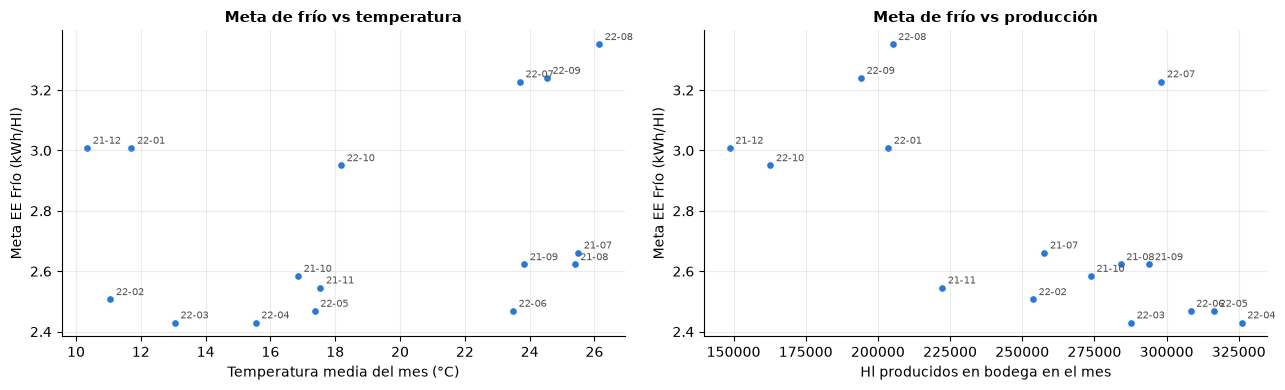

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, contra, etiqueta in [(axes[0], "temperatura mes", "Temperatura media del mes (°C)"),
                             (axes[1], "Hl Producido Bodega", "Hl producidos en bodega en el mes")]:
    ax.scatter(mensual[contra], mensual["Meta EE Frio"], s=40, color=SERIE[0],
               edgecolor="#fcfcfb", linewidth=1.5)
    for periodo, fila in mensual.iterrows():
        ax.annotate(periodo.strftime("%y-%m"), (fila[contra], fila["Meta EE Frio"]),
                    fontsize=7, xytext=(4, 3), textcoords="offset points", color="#52514e")
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("Meta EE Frío (kWh/Hl)")
axes[0].set_title("Meta de frío vs temperatura")
axes[1].set_title("Meta de frío vs producción")
plt.tight_layout()
plt.show()

In [34]:
# ¿La meta aporta información diaria? Frío "esperado" según la meta: Meta EE Frío × Hl de bodega del día.
esperado = tr["Meta EE Frio_Consolidado KPI"] * tr["Hl Producido Bodega_Consolidado Produccion"]
print(f"Frío esperado por la meta vs frío D: {esperado.corr(frio_tr, method='spearman'):.2f}")
print(f"Frío esperado por la meta vs y: {esperado.corr(y_tr, method='spearman'):.2f}")
print(f"Frío esperado por la meta vs y no explicado por persistencia: "
      f"{esperado.corr(y_no_explicado, method='spearman'):.2f}")

Frío esperado por la meta vs frío D: 0.59
Frío esperado por la meta vs y: 0.49
Frío esperado por la meta vs y no explicado por persistencia: 0.05


**Lectura:**

* **Producción: la hipótesis se sostiene.** Las metas de energía por hectolitro son **más altas en los meses de menor producción** (Meta EE Frío vs Hl de bodega: Spearman −0,65). Tiene sentido físico: buena parte del frío es carga fija (mantener tanques y cámaras), que se reparte entre menos hectolitros cuando se produce poco.
* **Temperatura: la evidencia es parcial.** La meta de frío sube con la temperatura (+0,42), pero con 16 meses el p-valor no permite afirmarlo. La meta de energía térmica (`Meta ET Planta`) sí sigue claramente a la estación, al revés (−0,73): se calienta más en invierno.
* **Las metas cambian por revisión anual.** El salto de julio de 2022 (de 2,47 a 3,23 kWh/Hl) coincide con el inicio de un nuevo ciclo de planificación, no con un cambio de temperatura ni de producción. Una parte importante de su variación es presupuestaria.
* **Aporte al pronóstico diario.** El frío "esperado" por la meta (meta × Hl de bodega) se relaciona con el frío (0,59 con el de hoy), pero frente a lo que no explica la persistencia su correlación es 0,05.

**Consecuencia para la selección:** las metas se conservan como candidatas, porque se conocen de antemano, pero lo esperable es que aporten poco por encima de los rezagos del frío. La selección lo decide con datos.

## 13. Exportación y comparación con el script

`ejecutar()` repite todo con `Pipeline`, exporta los CSV y la auditoría completa, y guarda el resumen con hashes. Comprobamos que produce exactamente las mismas predictoras que esta notebook.

* Datos: `data/processed/preprocesado_v2/` (`train.csv`, `validation.csv`, `test.csv`, `historial_completo.csv`)
* Auditoría: `results/auditoria_preprocesamiento/` (un CSV por paso, tablas de búsqueda, impacto, causalidad, LOF y `resumen.json`)

In [35]:
resultado = pv2.ejecutar(cfg)
datos_script = resultado["datos"]
pd.testing.assert_frame_equal(datos_script[X_proc.columns], X_proc, check_freq=False)
print("Las predictoras de la notebook y del script coinciden.")

carpeta = raiz / "results" / "auditoria_preprocesamiento"
display(pd.DataFrame({"archivo": sorted(p.name for p in carpeta.iterdir())}))

PREPROCESAMIENTO V2 (previo a la selección de variables)
Entrada        : 1172 días x 419 columnas
Ajuste hasta   : 2022-10-26 (solo Train)
  descartar_no_informativas  :  419 ->  352  {'conservar': 352, 'descartar': 67}
  unificar_renombradas       :  352 ->  349  {'unificar': 3}
  descartar_duplicadas       :  349 ->  316  {'conservar': 316, 'descartar': 33}
  filtrar_por_nulos          :  316 ->  287  {'conservar': 287, 'descartar': 29}
  outliers_univariados       :  287 ->  287  
  imputar_nulos              :  287 ->  289  
Causalidad     : OK
LOF            : k=35, PCA=59 comp., anómalos {'sin_etiqueta': 8, 'test': 114, 'train': 10, 'validation': 74}
Predictoras    : 289
Las predictoras de la notebook y del script coinciden.


,archivo
0,01_descartar_no_informativas.csv
1,02_unificar_renombradas.csv
2,03_descartar_duplicadas.csv
3,04_filtrar_por_nulos.csv
4,05_outliers_univariados.csv
5,05_outliers_univariados__comparacion_detectores.csv
6,06_imputar_nulos.csv
7,06_imputar_nulos__busqueda_imputacion.csv
8,impacto_por_paso.csv
9,lof_dias.csv


## 14. Conclusiones y decisiones pendientes

In [36]:
recorrido = pd.DataFrame([
    {"paso": n, "columnas de entrada": len(p.columnas_entrada_), "columnas de salida": len(p.columnas_salida_)}
    for n, p in pasos_ajustados])
display(recorrido)
print(f"Predictoras finales: {X_proc.shape[1]} | días de Train: {(particion == 'train').sum()} "
      f"| causalidad verificada: {bool(causalidad['causal'].all())}")

,paso,columnas de entrada,columnas de salida
0,descartar_no_informativas,419,352
1,unificar_renombradas,352,349
2,descartar_duplicadas,349,316
3,filtrar_por_nulos,316,287
4,outliers_univariados,287,287
5,imputar_nulos,287,289


Predictoras finales: 289 | días de Train: 798 | causalidad verificada: True


**Qué deja este preprocesamiento:**

* Predictoras sin nulos, en sus unidades originales y sin escalar. El escalado corresponde al modelo y se ajusta en Train.
* Una decisión documentada para cada columna, con su motivo, en `results/auditoria_preprocesamiento/`.
* Ningún parámetro estimado fuera de Train, con la causalidad verificada automáticamente.

**Lo que encontramos sobre producción y metas (secciones 11 y 12):**

* La producción del día se relaciona con el frío más allá de la estación, pero su aporte sobre la historia del frío es chico (Spearman ≤ 0,14 con lo que la persistencia no explica).
* Las metas por hectolitro son más altas en meses de baja producción; la relación con la temperatura es parcial, y gran parte del cambio es presupuestario (revisión anual de julio).

**Decisiones a tomar antes de la selección de variables:**

1. **Cambio de régimen en Validation y Test**: Mycom 2 apagado desde octubre de 2022, Mycom 1 con toda la carga y la línea de barriles L2 en marcha. Afecta directamente al consumo de frío. Opciones: agregar variables de *qué compresor opera*, usar ventanas de entrenamiento más recientes, o aceptar la degradación y medirla.
2. **Par `Tot L3, L4 y Planta de CO2`**: tiene un cociente de nivel de 1,74; confirmar que sea la misma medición.
3. **Tratamiento de outliers**: comparar en Validation `winsorizar` contra `ninguno`, y LOF `reportar` contra `excluir_train`.

**Próximo paso: selección de variables.** Candidatas = las predictoras de este preprocesamiento + rezagos y medias móviles del frío. Métodos: MOELIGA (algoritmo genético multiobjetivo) y selección hacia adelante (*forward selection*), con validación temporal dentro de Train.

**Cómo modificar el análisis:** los umbrales están en `Config`; los pasos se agregan o quitan en `construir_pasos()` (o con `--omitir` desde la terminal); los métodos de imputación y los detectores de outliers son diccionarios a los que se les puede agregar una función.